# CSCI1377 Lab 5: Visualization with Altair

In preparation for your upcoming assignment: Visualization, we've prepared this lab to get you acquainted with the tool you'll be using---a declarative library called [Vega-Altair](https://altair-viz.github.io/)! While other libraries like [MatPlotLib](https://matplotlib.org/), [Seaborn](https://seaborn.pydata.org/), and [Plotly](https://plotly.com/python/) afford a lot of flexibility in building visualizations, Altair is built as an opinionated, declarative library based on the grammar of graphics we've discussed in class.

## Materials

You should be completing this lab in-person with your TA as a resource, but you may find the following resources useful as reference:

**Altair documentation:** https://altair-viz.github.io/
- **Examples:** https://altair-viz.github.io/gallery/index.html
- **Marks:** https://altair-viz.github.io/user_guide/marks/index.html
- **Encodings:** https://altair-viz.github.io/user_guide/encodings/index.html


# Part 1: API Examples (TA-Guided)

> This part of the lab is meant to be completed with the interactive help of your TA. Part 2 is more freeform and exercise-based, so feel free to complete it independently or in lab if you have time!

Altair offers a declarative visualization library that relates data to visual encodings. To demonstrate this, we'll look at a few graphs made with Altair and then add to them. 

Below is the first example from Altair's ['getting started'](https://altair-viz.github.io/getting_started/overview.html) section of an interactive scatterplot. The useful thing to notice here is the data and encoding model. The "Chart" object is instantiated against its dataset, then set in its encoding type with [`mark_point()`](https://altair-viz.github.io/user_guide/marks/point.html) followed by a [`encode()`](https://altair-viz.github.io/user_guide/encodings/index.html) that describes which variables of the dataframe are visually encoded and their relationship to one another. The [`interactive()`](https://altair-viz.github.io/user_guide/interactions/index.html) declaration makes the output an interactive html5 chart.

In [87]:
# import altair with an abbreviated alias
import altair as alt

# load a sample dataset as a pandas DataFrame
from altair.datasets import data
cars = data.cars()

# make the chart
alt.Chart(cars).mark_point().encode(
    x='Horsepower',
    y='Miles_per_Gallon',
    color='Origin',
).interactive()

alt.Chart(...)

## Some more examples

Altair's api supports a number of different encoding schemes on both static and interactive visualizations. We'll go through a few, explain how they're expressed in the API, and then have you edit their encodings in various ways.

## About the data

Data for this part of this lab is from Altairs built-in 'movies' and 'cars' datasets (from [vega-datasets](https://github.com/vega/vega-datasets)).

# 1.1: A Quick Look at Your Data

While most of your tasks for this first section involve modifying existing charts, your later tasks will see you making your own. To help with this, it's useful to see how your dataset actually looks! Run the below cells.

In [88]:
films = data.movies()

films

,Title,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Release Date,MPAA Rating,Running Time min,Distributor,Source,Major Genre,Creative Type,Director,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
0,The Land Girls,146083,146083,<NA>,8000000,1998-06-12,R,<NA>,Gramercy,<NA>,<NA>,<NA>,<NA>,<NA>,6.1,1071
1,"First Love, Last Rites",10876,10876,<NA>,300000,1998-08-07,R,<NA>,Strand,<NA>,Drama,<NA>,<NA>,<NA>,6.9,207
2,I Married a Strange Person,203134,203134,<NA>,250000,1998-08-28,<NA>,<NA>,Lionsgate,<NA>,Comedy,<NA>,<NA>,<NA>,6.8,865
3,Let's Talk About Sex,373615,373615,<NA>,300000,1998-09-11,<NA>,<NA>,Fine Line,<NA>,Comedy,<NA>,<NA>,13,<NA>,<NA>
4,Slam,1009819,1087521,<NA>,1000000,1998-10-09,R,<NA>,Trimark,Original Screenplay,Drama,Contemporary Fiction,<NA>,62,3.4,165
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3196,Zack and Miri Make a Porno,31452765,36851125,21240321,24000000,2008-10-31,R,101,Weinstein Co.,Original Screenplay,Comedy,Contemporary Fiction,Kevin Smith,65,7.0,55687
3197,Zodiac,33080084,83080084,20983030,85000000,2007-03-02,R,157,Paramount Pictures,Based on Book/Short Story,Thriller/Suspense,Dramatization,David Fincher,89,<NA>,<NA>
3198,Zoom,11989328,12506188,6679409,35000000,2006-08-11,PG,<NA>,Sony Pictures,Based on Comic/Graphic Novel,Adventure,Super Hero,Peter Hewitt,3,3.4,7424
3199,The Legend of Zorro,45575336,141475336,<NA>,80000000,2005-10-28,PG,129,Sony Pictures,Remake,Adventure,Historical Fiction,Martin Campbell,26,5.7,21161


In [89]:
cars

,Name,Miles_per_Gallon,Cylinders,Displacement,Horsepower,Weight_in_lbs,Acceleration,Year,Origin
0,chevrolet chevelle malibu,18.0,8,307.0,130,3504,12.0,1970-01-01,USA
1,buick skylark 320,15.0,8,350.0,165,3693,11.5,1970-01-01,USA
2,plymouth satellite,18.0,8,318.0,150,3436,11.0,1970-01-01,USA
3,amc rebel sst,16.0,8,304.0,150,3433,12.0,1970-01-01,USA
4,ford torino,17.0,8,302.0,140,3449,10.5,1970-01-01,USA
...,...,...,...,...,...,...,...,...,...
401,ford mustang gl,27.0,4,140.0,86,2790,15.6,1982-01-01,USA
402,vw pickup,44.0,4,97.0,52,2130,24.6,1982-01-01,Europe
403,dodge rampage,32.0,4,135.0,84,2295,11.6,1982-01-01,USA
404,ford ranger,28.0,4,120.0,79,2625,18.6,1982-01-01,USA


## 1.2: Encoding Types

In class, you learned about how variables can be separated into levels of measurement: nominal, ordinal, and quantitative (if you forgot what these mean, check the slides [here!](https://cel.cs.brown.edu/csci-1377-f26/slides/10_Visualization_II.pdf)). Altair's declarative chart model builds on the grammar of graphics, so the way you choose to describe your variables affects the way they are displayed. 

In altair, any attribute set on a graph that can be appended with its intended encoding type: nominal, ordinal, temporal (we didn't talk about this one in class, but it just means dates/times), or quantitative, by appending a `:N`, `:O`, `:T`, or `:Q` after the name of the column in your dataset that variable comes from. For example, if I have a column `price`, `price:Q` would tell Altair that `price` is intended to be encoded as a quantitative variable!

[Encoding data types docs](https://altair-viz.github.io/user_guide/encodings/index.html#encoding-data-types)

**Task 1:** Change `Cylinders` from `:Q` to `:O` and compare the bars.

In [90]:
alt.Chart(cars).mark_bar().encode(
    x="Cylinders:Q",
    y="mean(Horsepower):Q"
)

alt.Chart(...)

If you don't supply an encoding type for a variable, Altair will attempt to infer what encoding type a variable is. It can do this relatively successfully, but it's important to consider how _you_ want variable types to be represented.

**Task 2:** The `color` encoding below has no type. Try `:Q`, `:O`, and `:N`. What changed in the legend and colors? Which type fits `Cylinders`, and why?

In [91]:
alt.Chart(cars).mark_point().encode(
    x="Horsepower:Q",
    y="Miles_per_Gallon:Q",
    color="Cylinders"
)

alt.Chart(...)

Sometimes Altair will infer ways to organize data we want to organize differently. You can more granularly control data on your axes using functions on `alt.X` and `alt.Y` classes in place of your x= and y= parameters.

**Task 3:** `MPAA Rating` is ordinal, but the bars come out in alphabetical order. Use `alt.X(..., sort=[...])` to put them in rating order (Hint: Check the [alt.X](https://altair-viz.github.io/user_guide/generated/channels/altair.X.html) documentation, Ctrl-F for 'sort', and check how you can sort values in an order manually specified).

In [92]:
rated = films.dropna(subset=["MPAA Rating"])

alt.Chart(rated).mark_bar().encode(
    x=alt.X("MPAA Rating:O"),
    y="count()"
)

alt.Chart(...)

## A Scatterplot (Movies)

Below is a scatterplot describing the IMDB Rating of movies vs. their Rotten Tomatoes rating. 

Try adding a color encoding for a movies' major genre (the key will be [color=](https://altair-viz.github.io/user_guide/encodings/channels.html)). What type of variable is this? Make sure to mark it in your encoding arguments. 

In [93]:
alt.Chart(films).mark_point().encode(
    x="Rotten Tomatoes Rating:Q",
    y="IMDB Rating:Q",
)


alt.Chart(...)

## 1.3: Aggregation

Sometimes, we want to work with data in aggregate. In these cases, we can handle things on the level of our data frames (e.g. adding a mean, median, etc. column), but Altair already supplies useful functions ready for our use. 
For any data encoded, you can wrap that data in an aggregation function (e.g. `median(<data>)`, `min(<data>),` `max(<data>)`) and the resulting visualization will show aggregate data. Note that this can also change related or dependent fields, which are treated as group-by fields in the aggregation process.

[Aggregation docs](https://altair-viz.github.io/user_guide/transform/aggregate.html)

**Task 1:** Change `y` to the mean MPG per year.

**Task 2:** Add a color encoding for `Origin`. How did the number of points change, and why?

**Task 3:** Swap `mean` for `median`, `min`, or `max`.

In [94]:
alt.Chart(cars).mark_point().encode(
    x="Year:T",
    y="Miles_per_Gallon:Q"
)

alt.Chart(...)

## 1.4: Changing Marks

In class, you also learned about marks and how different mark types can be used depending on what you're trying to represent. In Altair, charts are built first by specifying a mark type, so we'll explore some creative ones.
You can find the different types of marks in the [marks docs](https://altair-viz.github.io/user_guide/marks/index.html). While these aren't difficult to work with, there are certain visualizations that take more easily to mark types, and issues that can happen with particular mark types if we don't handle our data properly.

**Task 1:** Keep the encoding and change the mark to `mark_line()`, then `mark_area()`. What does the y-axis show in the area chart? Fix it with `alt.Y(...).stack(None)`.

In [95]:
alt.Chart(cars).mark_point().encode(
    x="Year:T",
    y="mean(Miles_per_Gallon):Q",
    color="Origin:N"
)

alt.Chart(...)

**Task 2:** 

The following is a chart that encodes Horsepower and Region of Origin of a set of cars produced in Europe, Japan, and the USA. Try changing this to a tick chart and then a boxplot chart and see how it changes (find the correct functions in the marks documentation)!

Change the mark to `mark_tick()`, then `mark_boxplot()`.

In [96]:
alt.Chart(cars).mark_point().encode(
    x="Horsepower:Q",
    y="Origin:N"
)

alt.Chart(...)

**Task 3:** Try turning this bubble chart into a heatmap! Marks should be rectangular, and the count of records should encode color instead of size.

In [97]:
alt.Chart(cars).mark_point().encode(
    x="Cylinders:O",
    y="Origin:N",
    size="count():Q"
)

alt.Chart(...)

## 1.5: Faceting

[Faceting docs](https://altair-viz.github.io/user_guide/compound_charts.html#faceted-charts)

Altair allows for the concatenation and layering of charts very easily. Layered charts are created by adding two charts together with the `+` operator, while charts can be horizontally concatenated with `|` or vertically with `&`. For example, if I have `chart1` and `chart2`, `chart1 + chart2` would layer them, `chart1 | chart2` would horizontally concatenate them, and `chart1 & chart2` would vertically concatenate them. You can also use the `alt.hconcat(<c1>, <c2>)` and `alt.vconcat(<c1>, <c2>)` to similar ends. Note that these operations create a _new_ chart. 

When we talk about _faceting_ charts, we mean providing multiple concatenated panels for different subsets of data. We can do this by appending an `alt.Chart` with the `.facet` function, which takes as argument a variable to facet by. You can also use the `rows` and `columns` channels for a more explicit control.

**Task 1:** Facet this chart into rows by `Origin` and columns by `Cylinders`. You can use `.properties(width=..., height=...)` to make the grid fit better, if you'd like.

**Task 2:** `color` now repeats what the rows show. Do you want to keep it or drop it? Why?

In [98]:
alt.Chart(cars).mark_point().encode(
    x="Horsepower:Q",
    y="Miles_per_Gallon:Q",
    color="Origin:N"
)

alt.Chart(...)

## 1.6 An Interactive Graph

One of Altair's most exciting affordances is the ease of adding interactivity to graphs. One way to do this is by adding the [.interactive()](https://altair-viz.github.io/user_guide/interactions/index.html) property to a graph, but there's much more to do! 

Try using Altair's [selection_interval()](https://altair-viz.github.io/user_guide/generated/api/altair.selection_interval.html#altair.selection_interval) to allow the user to select an area, then use its [.transform_filter()](https://altair-viz.github.io/user_guide/transform/filter.html) to adjust the bar chart depending on what's selected.

In [99]:
points = alt.Chart(cars).mark_point().encode(
    x="Horsepower:Q",
    y="Miles_per_Gallon:Q",
    color="Origin:N"
)

bars = alt.Chart(cars).mark_bar().encode(
    x="count():Q",
    y="Origin:N",
    color="Origin:N"
)

points & bars


alt.VConcatChart(...)

# Part 2: An Exercise in Visualization

In this section, you'll recreate visualizations and make one of your own based on a new dataset. This one is about Castles and Fortresses around the world. 

> This week we're exploring the [Castlemap](https://thecastlemap.com/data/) dataset of 5,793 castles, fortresses, palaces and ruins in 138 countries. The data comes from [Wikidata](https://www.wikidata.org/), and every landmark has verified coordinates, a [Wikipedia](https://www.wikipedia.org/) article and a photo on [Wikimedia Commons](https://commons.wikimedia.org/). Each also has a fame rank, based on how many languages have an article on it and how often that article is read. The Great Wall of China is first.

The cell below will import and sanitize data.

In [100]:
alt.data_transformers.enable("vegafusion")
import os
import shutil
import tempfile
from pathlib import Path
import pandas as pd
import pydytuesday

def fetch_data():
    data_dir = Path("data")
    data_dir.mkdir(exist_ok=True)
    cwd = Path.cwd()
    with tempfile.TemporaryDirectory() as tmp:
        os.chdir(tmp)
        try:
            pydytuesday.get_date("2026-09-01")
            for name in ["world_castles.csv", "world_castles.md"]:
                shutil.copy(Path(tmp) / name, cwd / data_dir / name)
        finally:
            os.chdir(cwd)

    return pd.read_csv(data_dir / "world_castles.csv")

castles = fetch_data()
castles

Trying to fetch README from: https://raw.githubusercontent.com/rfordatascience/tidytuesday/refs/heads/main/data/2026/2026-09-01/readme.md
Successfully fetched README from: https://raw.githubusercontent.com/rfordatascience/tidytuesday/refs/heads/main/data/2026/2026-09-01/readme.md
Successfully saved alhambra.png to /tmp/tmpvu0w0_a6/alhambra.png
Successfully saved cleaning.R to /tmp/tmpvu0w0_a6/cleaning.R
Successfully saved intro.md to /tmp/tmpvu0w0_a6/intro.md
Successfully saved meta.yaml to /tmp/tmpvu0w0_a6/meta.yaml
Successfully saved world_castles.csv to /tmp/tmpvu0w0_a6/world_castles.csv
Successfully saved world_castles.md to /tmp/tmpvu0w0_a6/world_castles.md


,qid,name,category,country,iso,lat,lon,year,year_approx,century,wikipedia,image,sitelinks,pageviews,fame_rank
0,Q12501,Great Wall of China,fortress,China,CN,40.43139,116.56444,-700.0,0,7th century BC,https://en.wikipedia.org/wiki/Great_Wall_of_China,https://commons.wikimedia.org/wiki/Special:Fil...,192,1441865.0,1
1,Q2946,Palace of Versailles,palace,France,FR,48.80472,2.12028,1661.0,0,17th century,https://en.wikipedia.org/wiki/Palace_of_Versai...,https://commons.wikimedia.org/wiki/Special:Fil...,108,756430.0,2
2,Q80290,Forbidden City,palace,China,CN,39.91583,116.39083,1420.0,0,15th century,https://en.wikipedia.org/wiki/Forbidden_City,https://commons.wikimedia.org/wiki/Special:Fil...,104,666289.0,3
3,Q1143049,Château de Montsoreau,castle,France,FR,47.21560,0.06220,990.0,0,10th century,https://en.wikipedia.org/wiki/Ch%C3%A2teau_de_...,https://commons.wikimedia.org/wiki/Special:Fil...,100,11059.0,430
4,Q131013,Acropolis of Athens,fortress,Greece,GR,37.97167,23.72611,-500.0,0,5th century BC,https://en.wikipedia.org/wiki/Acropolis_of_Athens,https://commons.wikimedia.org/wiki/Special:Fil...,96,542385.0,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5788,Q17061201,Yanxiang Lou,castle,China,CN,24.60910,116.97071,NaN,0,NaN,https://zh.wikipedia.org/wiki/%E8%A1%8D%E9%A6%...,https://commons.wikimedia.org/wiki/Special:Fil...,2,0.0,5711
5789,Q11069449,City walls in Shangqiu,fortress,China,CN,34.38775,115.61269,NaN,0,NaN,https://zh.wikipedia.org/wiki/%E5%BD%92%E5%BE%...,https://commons.wikimedia.org/wiki/Special:Fil...,2,0.0,5662
5790,Q15894367,Yangzuomie City Ruins,ruin,China,CN,25.70091,100.14555,NaN,0,NaN,https://zh.wikipedia.org/wiki/%E9%98%B3%E8%8B%...,https://commons.wikimedia.org/wiki/Special:Fil...,2,0.0,5675
5791,Q19856237,City Wall of Xiangcheng,fortress,China,CN,33.84921,113.46713,NaN,0,NaN,https://zh.wikipedia.org/wiki/%E8%A5%84%E5%9F%...,https://commons.wikimedia.org/wiki/Special:Fil...,2,0.0,5725


## 2.1: Graph Recreation 1: World Castles On The Map

**Task 1:** Recreate the graph below.

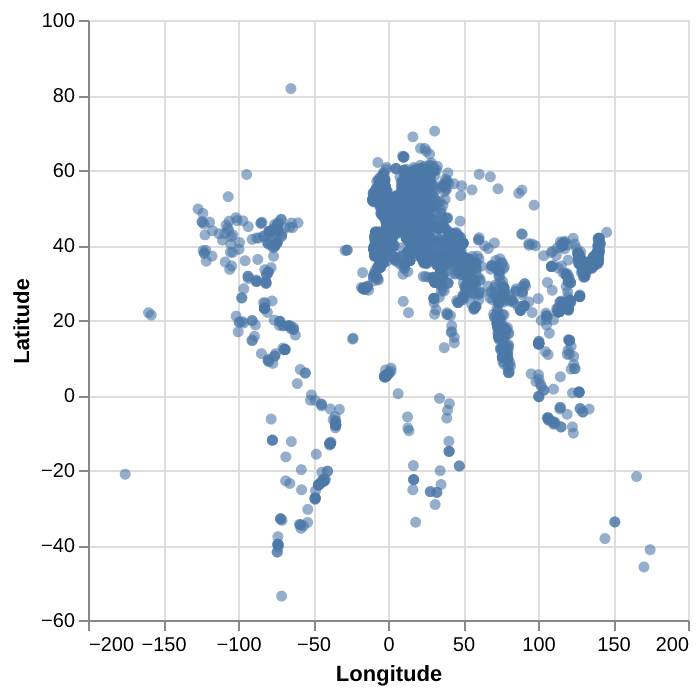

> **Relevant columns:** `lon`, `lat`

**Task 2:** Add a [color encoding](https://altair-viz.github.io/user_guide/encodings/channels.html) to your graph so that each point is colored by its `category`.

**Task 3:** Add a [tooltip](https://altair-viz.github.io/user_guide/encodings/channels.html) so that hovering over a point shows the landmark's `name`, `country` and `category`.

## 2.2: Graph Recreation 2: Countries and Castles, Palaces, and Fortresses

**Task 1:** Recreate the graph below.

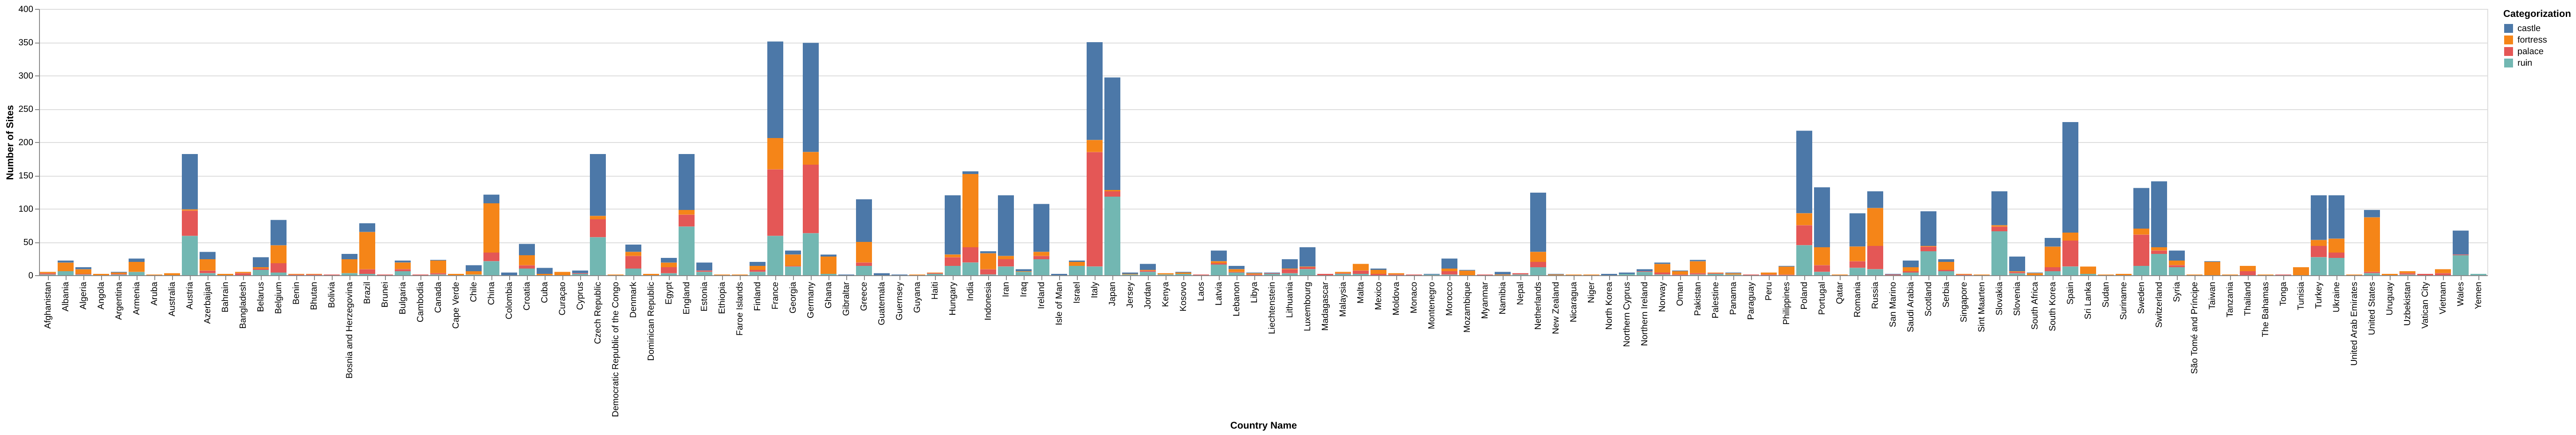

> **Relevant columns:** `country`, `category`

**Task 2:** Add interactivity to your graph! Clicking a category in the legend should highlight that category and dim the others.

## 2.3: When Did Fortresses Become More Popular than Castles?

Task: This time, we're letting you go free! Your task is to create an interesting visualization that illustrates when fortresses became more popular than castles. **You must create a graph that uses at least two of the following three visual tools: [interactivity](https://altair-viz.github.io/user_guide/interactions/index.html), redundant encoding, or [faceting and composition](https://altair-viz.github.io/user_guide/compound_charts.html)**. 

# Congratulations!

You've made it to the end of the lab! Hopefully you have enough to tackle assignment 5 head-on, but remember that you can always ask us questions on EdStem and come to hours. Good luck!